# 04. Perbandingan Model dan Analisis Risiko

Notebook ini merangkum hasil pipeline (`reports/hasil.json`), menguji apakah keunggulan SVR signifikan secara statistik dengan uji **Diebold-Mariano**, dan menambahkan modul **Value at Risk** sebagai pengembangan di luar skripsi.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from kurs_forecast.data import load_kurs, split_train_test
serie = load_kurs(); train, test = split_train_test(serie)
print(f"Total {len(serie)} minggu: training {len(train)}, testing {len(test)}")

Total 105 minggu: training 84, testing 21


In [2]:
import json
h = json.load(open(Path.cwd().parent / 'reports' / 'hasil.json' if Path.cwd().name == 'notebooks' else Path('reports/hasil.json')))
perbandingan = pd.DataFrame({
    'ARIMA (0,2,1) [repo]': h['arima']['metrik_test'],
    'SVR RBF [repo]': h['svr']['rbf']['metrik_test'],
    'SVR poly [repo]': h['svr']['poly']['metrik_test'],
    'ARIMA (0,2,1) [skripsi]': {**h['skripsi']['arima_test'], 'MAE': np.nan},
    'SVR RBF [skripsi]': {**h['skripsi']['svr_rbf_test'], 'MAE': np.nan},
}).T
perbandingan.round(3)

,RMSE,MAE,MAPE
"ARIMA (0,2,1) [repo]",421.049,377.016,2.473
SVR RBF [repo],93.600,76.871,0.509
SVR poly [repo],413.373,390.932,2.570
"ARIMA (0,2,1) [skripsi]",425.398,NaN,2.490
SVR RBF [skripsi],93.653,NaN,0.539


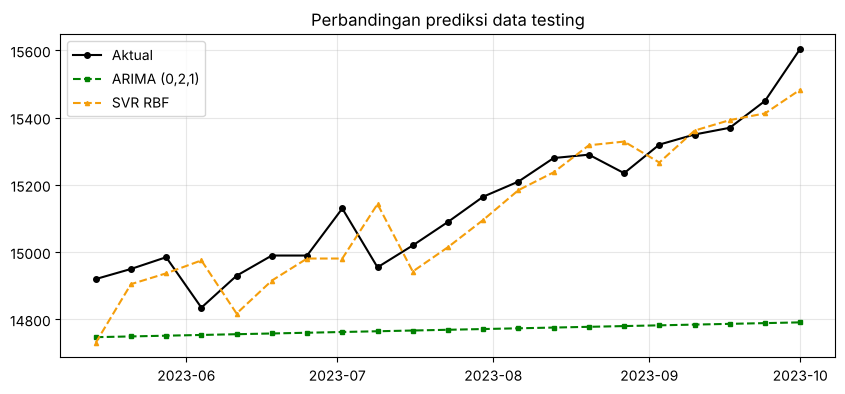

In [3]:
prediksi = pd.read_csv(Path.cwd().parent / 'data/processed/prediksi_testing.csv' if Path.cwd().name == 'notebooks' else 'data/processed/prediksi_testing.csv', parse_dates=['tanggal'])
plt.figure(figsize=(10,4.2))
plt.plot(prediksi.tanggal, prediksi.aktual, 'k-o', ms=4, label='Aktual')
plt.plot(prediksi.tanggal, prediksi.arima, 'g--s', ms=3, label='ARIMA (0,2,1)')
plt.plot(prediksi.tanggal, prediksi.svr_rbf, '--^', color='#f59e0b', ms=3, label='SVR RBF')
plt.legend(); plt.grid(alpha=.3); plt.title('Perbandingan prediksi data testing');

## Uji Diebold-Mariano
Membandingkan RMSE saja tidak menjawab apakah selisihnya nyata atau kebetulan. Uji DM (dengan koreksi Harvey-Leybourne-Newbold) menguji H0: kedua model sama akuratnya. Statistik negatif berarti model pertama (SVR) lebih akurat.

In [4]:
h['diebold_mariano_svr_vs_arima']

{'dm_statistic': -4.545989825837644,
 'pvalue': 0.0001965527758928937,
 'model_1_lebih_baik': True}

## Value at Risk dari return kurs
Pertanyaan praktis untuk tim treasury atau risiko: jika perusahaan punya kewajiban 100.000 USD, berapa tambahan rupiah terburuk yang perlu disiapkan dalam satu minggu pada keyakinan 95%?

In [5]:
from kurs_forecast.risk import ringkasan_risiko, log_returns
from kurs_forecast.plots import plot_var
r = ringkasan_risiko(serie)
plot_var(log_returns(serie), r['var_historis_pct']/100, r['var_parametrik_pct']/100);
pd.Series(r).round(4)

alpha                 5.000000e-02
n_return              1.040000e+02
mean_return_pct       8.940000e-02
std_return_pct        7.947000e-01
var_historis_pct      1.193200e+00
var_parametrik_pct    1.396500e+00
es_historis_pct       1.411200e+00
nominal_usd           1.000000e+05
kurs_akhir            1.560500e+04
var_historis_rp       1.873137e+07
var_parametrik_rp     2.194536e+07
es_historis_rp        2.217738e+07
dtype: float64

## Kesimpulan
1. SVR kernel RBF mengungguli ARIMA (0,2,1) pada data testing, dan keunggulan itu signifikan secara statistik (uji DM p < 0,05).
2. Keunggulan SVR berlaku untuk peramalan satu langkah; pada skema rekursif 21 minggu akurasinya turun ke level ARIMA, sehingga pemilihan model harus mengikuti horizon kebutuhan bisnis.
3. Risiko pelemahan rupiah mingguan pada keyakinan 95% berada di kisaran 1,2 sampai 1,4% (VaR), dengan expected shortfall sedikit lebih tinggi.